# Exploratory Data Analysis & Preprocessing

This notebook examines the synthetic football dataset, checks how its files join, and builds a leakage-aware window-level table for later modeling. It keeps the source CSVs unchanged.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

In [2]:

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

REQUIRED_FILES = {
    "matches": "matches.csv",
    "events": "events.csv",
    "players": "players.csv",
    "windows": "match_windows.csv",
    "labels": "ground_truth_labels.csv",
    "evaluation_cases": "evaluation_cases.csv",
}

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (root for root in candidate_roots if all((root / "data" / filename).is_file() for filename in REQUIRED_FILES.values())),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the repository data folder from the notebook working directory.")

DATA_DIR = PROJECT_ROOT / "data"
tables = {name: pd.read_csv(DATA_DIR / filename, low_memory=False) for name, filename in REQUIRED_FILES.items()}
matches = tables["matches"]
events = tables["events"]
players = tables["players"]
windows = tables["windows"]
labels = tables["labels"]
evaluation_cases = tables["evaluation_cases"]
dictionary = json.loads((DATA_DIR / "data_dictionary.json").read_text(encoding="utf-8"))

print(f"Project: {PROJECT_ROOT}")
print("Loaded table shapes:")
print(pd.DataFrame({
    "rows": {name: len(frame) for name, frame in tables.items()},
    "columns": {name: len(frame.columns) for name, frame in tables.items()},
}).to_string())

Project: d:\Lean\fa_fo\invisible-game-hackathon
Loaded table shapes:
                   rows  columns
matches              60       12
events            17280       24
players            1320        5
windows             360       18
labels              360        8
evaluation_cases    180        9


## 1. Load the source tables

In [3]:
print("Column inventory")
for name, frame in tables.items():
    print()
    print(f"{name} ({len(frame):,} rows)")
    print(", ".join(frame.columns))

print()
print("Dataset declaration")
print(json.dumps(dictionary.get("dataset_size", {}), indent=2))
print()
print("Data origin values")
for name, frame in tables.items():
    if "data_origin" in frame:
        print(f"{name}: {frame['data_origin'].value_counts(dropna=False).to_dict()}")

Column inventory

matches (60 rows)
match_id, home_team, away_team, competition, match_date, scenario_type, scenario_title, subject_team, opponent_team, ground_truth_persistent_risk, scenario_description, data_origin

events (17,280 rows)
event_id, match_id, timestamp_seconds, minute, period, team_name, player_id, player_position, event_type, outcome, possession_id, x, y, pitch_zone, pitch_lane, pressure_intensity, defenders_behind_ball, recovery_speed_index, fatigue_index, xg, is_subject_team, data_origin, is_dangerous_turnover, is_attacking_entry

players (1,320 rows)
player_id, team_name, position, player_name, data_origin

windows (360 rows)
window_id, match_id, subject_team, window_start_seconds, window_end_seconds, window_start_minute, window_end_minute, subject_possession_share, subject_turnovers, dangerous_turnovers_observed, opponent_attacking_entries, avg_subject_recovery_speed, avg_subject_defenders_behind_ball, expert_transient_spike_label, expert_persistent_risk_label, exp

## 2. Inventory and provenance

In [4]:
key_columns = {
    "matches": "match_id",
    "events": "event_id",
    "players": "player_id",
    "windows": "window_id",
    "labels": "window_id",
    "evaluation_cases": "evaluation_id",
}
quality_rows = []
for name, frame in tables.items():
    key = key_columns[name]
    quality_rows.append({
        "table": name,
        "rows": len(frame),
        "columns": len(frame.columns),
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_rows": int(frame.duplicated().sum()),
        "duplicate_keys": int(frame[key].duplicated().sum()),
    })
quality = pd.DataFrame(quality_rows).set_index("table")
print("Missing values and key uniqueness")
print(quality.to_string())

player_join = events.merge(
    players[["player_id", "team_name", "position"]],
    on="player_id", how="left", validate="many_to_one", suffixes=("", "_roster"), indicator=True,
)
match_id_set = set(matches["match_id"])
join_summary = pd.Series({
    "events without roster match": int((player_join["_merge"] != "both").sum()),
    "event team vs roster mismatch": int((player_join["team_name"] != player_join["team_name_roster"]).sum()),
    "event position vs roster mismatch": int((player_join["player_position"] != player_join["position"]).sum()),
    "unique player names": int(players["player_name"].nunique()),
    "duplicate player names": int(players["player_name"].duplicated().sum()),
    "blank player names": int(players["player_name"].isna().sum() + players["player_name"].astype(str).str.strip().eq("").sum()),
    "events with unknown match": int((~events["match_id"].isin(match_id_set)).sum()),
    "windows with unknown match": int((~windows["match_id"].isin(match_id_set)).sum()),
    "duplicate event IDs": int(events["event_id"].duplicated().sum()),
    "duplicate player IDs": int(players["player_id"].duplicated().sum()),
    "duplicate window IDs": int(windows["window_id"].duplicated().sum()),
})
print()
print("Join and identifier checks (expected: zero)")
print(join_summary.to_string())

print()
print("Missing values by table (only nonzero columns)")
for name, frame in tables.items():
    missing = frame.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    if missing.empty:
        print(f"{name}: none")
    else:
        print(f"{name}:")
        print(missing.to_string())

Missing values and key uniqueness
                   rows  columns  missing_cells  duplicate_rows  duplicate_keys
table                                                                          
matches              60       12              0               0               0
events            17280       24          16785               0               0
players            1320        5              0               0               0
windows             360       18              0               0               0
labels              360        8              0               0               0
evaluation_cases    180        9              0               0               0

Join and identifier checks (expected: zero)
events without roster match             0
event team vs roster mismatch           0
event position vs roster mismatch       0
unique player names                  1320
duplicate player names                  0
blank player names                      0
events with unknown match    

## 3. Data quality and joins

In [5]:
# Convert measurement columns to numeric types while retaining the original CSV files.
event_numeric = ["timestamp_seconds", "minute", "x", "y", "pressure_intensity",
                 "defenders_behind_ball", "recovery_speed_index", "fatigue_index", "xg"]
window_numeric = ["window_start_seconds", "window_end_seconds", "window_start_minute", "window_end_minute",
                  "subject_possession_share", "subject_turnovers", "dangerous_turnovers_observed",
                  "opponent_attacking_entries", "avg_subject_recovery_speed",
                  "avg_subject_defenders_behind_ball", "expert_risk_intensity"]
for column in event_numeric:
    events[column] = pd.to_numeric(events[column], errors="coerce")
for column in window_numeric:
    windows[column] = pd.to_numeric(windows[column], errors="coerce")
for column in ["is_subject_team", "is_dangerous_turnover", "is_attacking_entry"]:
    events[column] = pd.to_numeric(events[column], errors="coerce").fillna(0).astype("int8")
for column in ["expert_persistent_risk_label", "expert_transient_spike_label"]:
    windows[column] = pd.to_numeric(windows[column], errors="coerce").astype("int8")
labels["risk_label"] = pd.to_numeric(labels["risk_label"], errors="coerce").astype("int8")
labels["transient_spike_label"] = pd.to_numeric(labels["transient_spike_label"], errors="coerce").astype("int8")

range_checks = {
    "pressure outside [0, 1]": int((~events["pressure_intensity"].between(0, 1)).sum()),
    "recovery outside [0, 1]": int((~events["recovery_speed_index"].between(0, 1)).sum()),
    "fatigue outside [0, 1]": int((~events["fatigue_index"].between(0, 1)).sum()),
    "possession share outside [0, 1]": int((~windows["subject_possession_share"].between(0, 1)).sum()),
    "non-binary event flags": int(sum((~events[column].isin([0, 1])).sum() for column in
                                       ["is_subject_team", "is_dangerous_turnover", "is_attacking_entry"])),
}
print("Range and flag checks (expected: zero exceptions)")
print(pd.Series(range_checks).to_string())
print()
print("Event-type counts")
print(events["event_type"].value_counts().rename_axis("event_type").to_string())
print()
print("Pitch-zone counts")
print(events["pitch_zone"].value_counts().rename_axis("pitch_zone").to_string())

Range and flag checks (expected: zero exceptions)
pressure outside [0, 1]            0
recovery outside [0, 1]            0
fatigue outside [0, 1]             0
possession share outside [0, 1]    0
non-binary event flags             0

Event-type counts
event_type
pass            6027
turnover        3297
carry           2793
cross           1095
pressure         849
tackle           823
interception     770
recovery         625
clearance        506
shot             495

Pitch-zone counts
pitch_zone
attacking_third    8895
middle_third       5174
defensive_third    3211


## 4. Type normalization and range checks

In [6]:
# Map events to 15-minute windows using each match's actual window boundaries.
window_bounds = windows[["window_id", "match_id", "window_start_seconds", "window_end_seconds"]]
event_window_candidates = events.merge(window_bounds, on="match_id", how="left", validate="many_to_many")
event_window = event_window_candidates.loc[
    event_window_candidates["timestamp_seconds"].ge(event_window_candidates["window_start_seconds"])
    & event_window_candidates["timestamp_seconds"].lt(event_window_candidates["window_end_seconds"])
].copy()
mapping_counts = event_window["event_id"].value_counts()
print("Event-to-window mapping")
print(pd.Series({
    "source events": len(events),
    "events mapped to exactly one window": int((mapping_counts == 1).sum()),
    "events mapped zero or multiple times": int(len(events) - (mapping_counts == 1).sum()),
    "events outside all windows": int((~events["event_id"].isin(mapping_counts.index)).sum()),
}).to_string())

event_window["subject_turnover"] = (
    event_window["is_subject_team"].eq(1) & event_window["event_type"].eq("turnover")
).astype("int8")
event_window["subject_pressure"] = event_window["pressure_intensity"].where(event_window["is_subject_team"].eq(1))
event_window["subject_fatigue"] = event_window["fatigue_index"].where(event_window["is_subject_team"].eq(1))
event_window["opponent_fatigue"] = event_window["fatigue_index"].where(event_window["is_subject_team"].eq(0))
event_window["dangerous_pressure"] = event_window["pressure_intensity"].where(event_window["is_dangerous_turnover"].eq(1))
event_window["entry_x"] = event_window["x"].where(event_window["is_attacking_entry"].eq(1))
event_window["subject_shot"] = (
    event_window["is_subject_team"].eq(1) & event_window["event_type"].eq("shot")
).astype("int8")
event_window["opponent_shot"] = (
    event_window["is_subject_team"].eq(0) & event_window["event_type"].eq("shot")
).astype("int8")

event_features = event_window.groupby("window_id").agg(
    event_rows=("event_id", "size"),
    event_subject_turnovers=("subject_turnover", "sum"),
    event_dangerous_turnovers=("is_dangerous_turnover", "sum"),
    event_attacking_entries=("is_attacking_entry", "sum"),
    subject_pressure_mean=("subject_pressure", "mean"),
    subject_fatigue_mean=("subject_fatigue", "mean"),
    opponent_fatigue_mean=("opponent_fatigue", "mean"),
    dangerous_turnover_pressure_mean=("dangerous_pressure", "mean"),
    attacking_entry_x_mean=("entry_x", "mean"),
    subject_shots=("subject_shot", "sum"),
    opponent_shots=("opponent_shot", "sum"),
).reset_index()

reconciled = windows.merge(event_features, on="window_id", how="left", validate="one_to_one")
reconciliation = pd.Series({
    "subject turnover count mismatches": int((reconciled["event_subject_turnovers"] != reconciled["subject_turnovers"]).sum()),
    "dangerous-turnover flag mismatches": int((reconciled["event_dangerous_turnovers"] != reconciled["dangerous_turnovers_observed"]).sum()),
    "attacking-entry flag mismatches": int((reconciled["event_attacking_entries"] != reconciled["opponent_attacking_entries"]).sum()),
    "windows without event rows": int(reconciled["event_rows"].isna().sum()),
})
print()
print("Event-derived aggregate reconciliation (expected: zero mismatches)")
print(reconciliation.to_string())
if reconciliation.ne(0).any():
    raise ValueError("Event-derived counts do not reconcile with match_windows.csv")
print()
print("Event-derived feature preview")
print(event_features.head(8).to_string(index=False))

Event-to-window mapping
source events                           17280
events mapped to exactly one window     17280
events mapped zero or multiple times        0
events outside all windows                  0

Event-derived aggregate reconciliation (expected: zero mismatches)
subject turnover count mismatches     0
dangerous-turnover flag mismatches    0
attacking-entry flag mismatches       0
windows without event rows            0

Event-derived feature preview
window_id  event_rows  event_subject_turnovers  event_dangerous_turnovers  event_attacking_entries  subject_pressure_mean  subject_fatigue_mean  opponent_fatigue_mean  dangerous_turnover_pressure_mean  attacking_entry_x_mean  subject_shots  opponent_shots
IGM001_W1          48                       12                          1                        3               0.539000              0.183625               0.181812                          0.823000               79.510000              0               1
IGM001_W2          48

## 5. Event-to-window mapping and reconciliation

In [7]:
print("Match-level persistent-risk labels by archetype")
match_balance = pd.crosstab(matches["scenario_type"], matches["ground_truth_persistent_risk"])
print(match_balance.to_string())
print()
print("Window-level persistent-risk and transient-spike labels")
window_labels = pd.crosstab(windows["expert_persistent_risk_label"], windows["expert_transient_spike_label"])
print(window_labels.to_string())
print()
print("Label counts")
print(pd.Series({
    "positive matches": int(matches["ground_truth_persistent_risk"].sum()),
    "matches": len(matches),
    "positive windows": int(windows["expert_persistent_risk_label"].sum()),
    "windows": len(windows),
    "transient-spike windows": int(windows["expert_transient_spike_label"].sum()),
}).to_string())
print(f"Window persistent-risk prevalence: {windows['expert_persistent_risk_label'].mean():.1%}")
print(f"Transient-spike prevalence: {windows['expert_transient_spike_label'].mean():.1%}")

Match-level persistent-risk labels by archetype
ground_truth_persistent_risk  0  1
scenario_type                     
balanced_match                2  3
chaotic_endgame               2  3
counter_threat                3  2
false_alarm                   3  2
late_fatigue                  3  2
left_side_exposure            3  2
low_block                     2  3
possession_trap               2  3
pressing_bait                 2  3
recovery_success              3  2
score_effect                  2  3
single_event_noise            3  2

Window-level persistent-risk and transient-spike labels
expert_transient_spike_label    0  1
expert_persistent_risk_label        
0                             268  6
1                              86  0

Label counts
positive matches            30
matches                     60
positive windows            86
windows                    360
transient-spike windows      6
Window persistent-risk prevalence: 23.9%
Transient-spike prevalence: 1.7%


## 6. Labels and class balance

In [8]:
# Summaries describe relationships in synthetic data; they do not establish causation.
profile_columns = ["subject_turnovers", "dangerous_turnovers_observed", "opponent_attacking_entries",
                   "avg_subject_recovery_speed", "avg_subject_defenders_behind_ball", "expert_risk_intensity"]
profile = windows.groupby("expert_persistent_risk_label")[profile_columns].agg(["median", "mean"]).round(2)
print("Window feature summaries by persistent-risk label (0 = absent, 1 = present)")
print(profile.to_string())

turnover_threshold = 9
baseline_pred = windows["subject_turnovers"].ge(turnover_threshold).astype("int8")
truth = windows["expert_persistent_risk_label"]
tp = int(((baseline_pred == 1) & (truth == 1)).sum())
fp = int(((baseline_pred == 1) & (truth == 0)).sum())
fn = int(((baseline_pred == 0) & (truth == 1)).sum())
tn = int(((baseline_pred == 0) & (truth == 0)).sum())
baseline = pd.DataFrame([[tn, fp], [fn, tp]],
                        index=["actual 0", "actual 1"], columns=["predicted 0", "predicted 1"])
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
print()
print(f"Simple turnover baseline: predict risk when subject_turnovers >= {turnover_threshold}")
print(baseline.to_string())
print(f"precision={precision:.3f}; recall={recall:.3f}. Descriptive only; this uses no held-out split.")

Window feature summaries by persistent-risk label (0 = absent, 1 = present)
                             subject_turnovers        dangerous_turnovers_observed       opponent_attacking_entries       avg_subject_recovery_speed       avg_subject_defenders_behind_ball       expert_risk_intensity      
                                        median   mean                       median  mean                     median  mean                     median  mean                            median  mean                median  mean
expert_persistent_risk_label                                                                                                                                                                                                  
0                                          8.0   7.57                          1.0  1.03                        4.0  4.26                       0.76  0.76                              4.68  4.70                  0.29  0.28
1                               

## 7. Signal summaries and a simple baseline

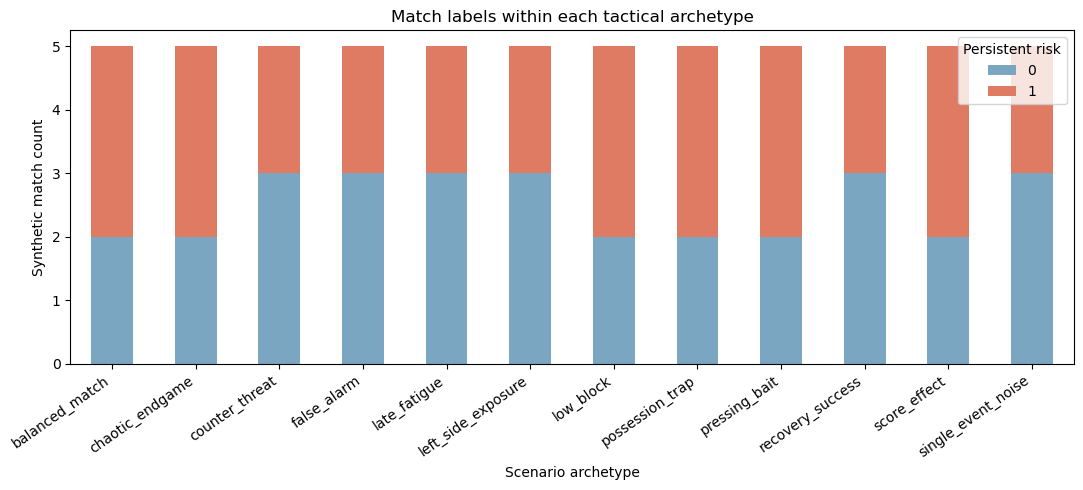

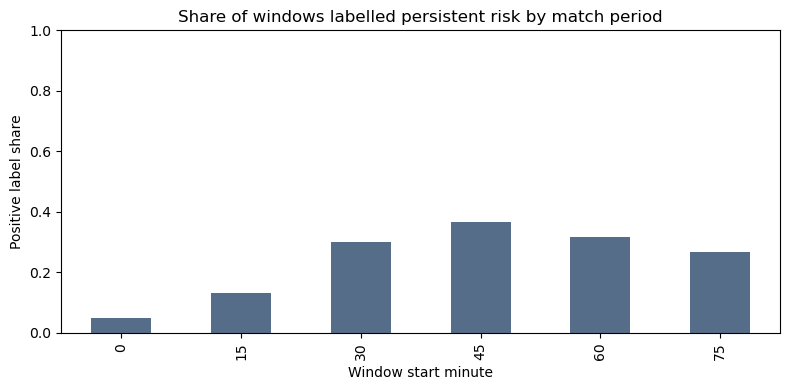

In [9]:
# Optional charts. The exact tables above remain available if Matplotlib is absent.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib is not installed; the tables above provide exact counts.")
else:
    ax = match_balance.plot(kind="bar", stacked=True, figsize=(11, 5), color=["#7aa6c2", "#df7b63"])
    ax.set_title("Match labels within each tactical archetype")
    ax.set_xlabel("Scenario archetype")
    ax.set_ylabel("Synthetic match count")
    ax.legend(title="Persistent risk")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

    risk_by_window = windows.groupby("window_start_minute")["expert_persistent_risk_label"].mean()
    ax = risk_by_window.plot(kind="bar", figsize=(8, 4), color="#566d8a")
    ax.set_title("Share of windows labelled persistent risk by match period")
    ax.set_xlabel("Window start minute")
    ax.set_ylabel("Positive label share")
    ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 8. Temporal patterns

In [10]:
print("Persistent-risk windows by 15-minute period")
temporal = windows.groupby(["window_start_minute", "window_end_minute"]).agg(
    windows=("window_id", "count"),
    positive_risk_windows=("expert_persistent_risk_label", "sum"),
    transient_spikes=("expert_transient_spike_label", "sum"),
    mean_turnovers=("subject_turnovers", "mean"),
).reset_index()
temporal["risk_share"] = temporal["positive_risk_windows"] / temporal["windows"]
print(temporal.round(2).to_string(index=False))

print()
print("Dangerous events and attacking entries by event type")
flag_summary = events.groupby("event_type").agg(
    events=("event_id", "count"),
    dangerous_turnovers=("is_dangerous_turnover", "sum"),
    attacking_entries=("is_attacking_entry", "sum"),
).sort_values("events", ascending=False)
print(flag_summary.to_string())

Persistent-risk windows by 15-minute period
 window_start_minute  window_end_minute  windows  positive_risk_windows  transient_spikes  mean_turnovers  risk_share
                   0                 15       60                      3                 0            7.40        0.05
                  15                 30       60                      8                 3            8.33        0.13
                  30                 45       60                     18                 1            8.50        0.30
                  45                 60       60                     22                 1            8.60        0.37
                  60                 75       60                     19                 0            8.25        0.32
                  75                 90       60                     16                 1            7.87        0.27

Dangerous events and attacking entries by event type
              events  dangerous_turnovers  attacking_entries
event_type     

## 9. Leakage audit

In [11]:
print("Potential leakage fields — keep out of model inputs")
leakage_notes = [
    ("expert_persistent_risk_label / risk_label", "The target label itself."),
    ("expert_transient_spike_label / transient_spike_label", "A second target; use only for its own task or evaluation."),
    ("expert_risk_intensity / risk_intensity", "Constructed from the same tactical signals; not an independent predictor."),
    ("ground_truth_persistent_risk", "Match-level target derived from window labels."),
    ("scenario_type / scenario_title / scenario_description", "Scenario metadata; useful for grouped splitting, not default features."),
    ("match_id / window_id / event_id / player_id", "Identifiers, not predictive measurements."),
    ("evaluation_cases.csv criteria", "Evaluation prompts and expected-answer hints; never model inputs."),
    ("data_origin", "Constant provenance metadata."),
]
print(pd.DataFrame(leakage_notes, columns=["field", "reason"]).to_string(index=False))
print()
print("Recommended evaluation: keep all windows from each match together. For a stricter transfer check, hold out whole scenario_type groups.")

Potential leakage fields — keep out of model inputs
                                                field                                                                    reason
            expert_persistent_risk_label / risk_label                                                  The target label itself.
 expert_transient_spike_label / transient_spike_label                 A second target; use only for its own task or evaluation.
               expert_risk_intensity / risk_intensity Constructed from the same tactical signals; not an independent predictor.
                         ground_truth_persistent_risk                            Match-level target derived from window labels.
scenario_type / scenario_title / scenario_description    Scenario metadata; useful for grouped splitting, not default features.
          match_id / window_id / event_id / player_id                                 Identifiers, not predictive measurements.
                        evaluation_cases.csv criteri

## 10. Build the window-level modeling table

In [12]:
# One row per match window, joining labels, match metadata, and event-derived summaries.
label_columns = labels[["window_id", "match_id", "risk_label", "transient_spike_label"]].rename(columns={
    "risk_label": "label_risk_joined",
    "transient_spike_label": "label_transient_joined",
})
match_metadata = matches[["match_id", "ground_truth_persistent_risk", "scenario_type"]].rename(columns={
    "ground_truth_persistent_risk": "match_persistent_target",
    "scenario_type": "match_scenario_type",
})

model_table = (
    windows.merge(label_columns, on=["window_id", "match_id"], how="left", validate="one_to_one")
    .merge(match_metadata, on="match_id", how="left", validate="many_to_one")
    .merge(event_features, on="window_id", how="left", validate="one_to_one")
)
model_table["target_persistent_risk"] = model_table["expert_persistent_risk_label"].astype("int8")
label_join_mismatches = int((model_table["target_persistent_risk"] != model_table["label_risk_joined"]).sum())
transient_join_mismatches = int((model_table["expert_transient_spike_label"] != model_table["label_transient_joined"]).sum())
scenario_join_mismatches = int((model_table["scenario_type"] != model_table["match_scenario_type"]).sum())
print("Prepared window table")
print(f"rows={len(model_table):,}; columns={len(model_table.columns)}")
print(f"persistent-label mismatches={label_join_mismatches}; transient-label mismatches={transient_join_mismatches}; scenario mismatches={scenario_join_mismatches}")
print(model_table[["match_id", "window_id", "window_start_minute", "scenario_type",
                   "subject_turnovers", "dangerous_turnovers_observed", "opponent_attacking_entries",
                   "target_persistent_risk"]].head(8).to_string(index=False))

Prepared window table
rows=360; columns=34
persistent-label mismatches=0; transient-label mismatches=0; scenario mismatches=0
match_id window_id  window_start_minute   scenario_type  subject_turnovers  dangerous_turnovers_observed  opponent_attacking_entries  target_persistent_risk
  IGM001 IGM001_W1                    0 possession_trap                 12                             1                           3                       0
  IGM001 IGM001_W2                   15 possession_trap                  8                             2                           6                       0
  IGM001 IGM001_W3                   30 possession_trap                 12                             7                           8                       1
  IGM001 IGM001_W4                   45 possession_trap                 11                             6                          11                       1
  IGM001 IGM001_W5                   60 possession_trap                  8               

## 11. Add prior-only temporal features

In [13]:
# Add only backward-looking history. shift(1) prevents use of future windows.
model_table = model_table.sort_values(["match_id", "window_start_seconds"]).reset_index(drop=True)
grouped = model_table.groupby("match_id", sort=False)
model_table["prior_3w_dangerous_turnovers"] = grouped["dangerous_turnovers_observed"].transform(
    lambda values: values.shift(1).rolling(3, min_periods=1).sum()
).fillna(0)
grouped = model_table.groupby("match_id", sort=False)
model_table["prior_3w_attacking_entries"] = grouped["opponent_attacking_entries"].transform(
    lambda values: values.shift(1).rolling(3, min_periods=1).sum()
).fillna(0)
grouped = model_table.groupby("match_id", sort=False)
model_table["prior_3w_recovery_mean"] = grouped["avg_subject_recovery_speed"].transform(
    lambda values: values.shift(1).rolling(3, min_periods=1).mean()
)

FEATURE_COLUMNS = [
    "subject_possession_share",
    "subject_turnovers",
    "dangerous_turnovers_observed",
    "opponent_attacking_entries",
    "avg_subject_recovery_speed",
    "avg_subject_defenders_behind_ball",
    "subject_pressure_mean",
    "subject_fatigue_mean",
    "opponent_fatigue_mean",
    "dangerous_turnover_pressure_mean",
    "attacking_entry_x_mean",
    "subject_shots",
    "opponent_shots",
    "prior_3w_dangerous_turnovers",
    "prior_3w_attacking_entries",
    "prior_3w_recovery_mean",
]
TARGET_COLUMN = "target_persistent_risk"
print(f"Modeling feature count: {len(FEATURE_COLUMNS)}")
print("Feature list:")
print("\n".join(f"- {name}" for name in FEATURE_COLUMNS))
print()
print("Target distribution")
print(model_table[TARGET_COLUMN].value_counts().sort_index().rename(
    index={0: "no persistent risk", 1: "persistent risk"}
).to_string())
print()
print("Missing values in selected numeric features")
print(model_table[FEATURE_COLUMNS].isna().sum().sort_values(ascending=False).to_string())

Modeling feature count: 16
Feature list:
- subject_possession_share
- subject_turnovers
- dangerous_turnovers_observed
- opponent_attacking_entries
- avg_subject_recovery_speed
- avg_subject_defenders_behind_ball
- subject_pressure_mean
- subject_fatigue_mean
- opponent_fatigue_mean
- dangerous_turnover_pressure_mean
- attacking_entry_x_mean
- subject_shots
- opponent_shots
- prior_3w_dangerous_turnovers
- prior_3w_attacking_entries
- prior_3w_recovery_mean

Target distribution
target_persistent_risk
no persistent risk    274
persistent risk        86

Missing values in selected numeric features
dangerous_turnover_pressure_mean     89
prior_3w_recovery_mean               60
subject_possession_share              0
subject_turnovers                     0
dangerous_turnovers_observed          0
opponent_attacking_entries            0
avg_subject_recovery_speed            0
avg_subject_defenders_behind_ball     0
subject_pressure_mean                 0
subject_fatigue_mean                 

## 12. Grouped evaluation split

In [14]:
# Hold out entire archetypes instead of random windows so sibling variants do not cross the split.
scenario_types = sorted(model_table["scenario_type"].dropna().unique())
rng = np.random.default_rng(20261022)
test_scenarios = set(rng.choice(
    scenario_types, size=max(1, round(len(scenario_types) * 0.25)), replace=False
).tolist())
train_mask = ~model_table["scenario_type"].isin(test_scenarios)
train_rows = model_table.loc[train_mask].copy()
test_rows = model_table.loc[~train_mask].copy()

print(f"Held-out archetypes ({len(test_scenarios)} of {len(scenario_types)}): {sorted(test_scenarios)}")
split_summary = pd.DataFrame([
    {"split": "train", "windows": len(train_rows), "matches": train_rows["match_id"].nunique(),
     "risk_positive_share": train_rows[TARGET_COLUMN].mean(), "archetypes": train_rows["scenario_type"].nunique()},
    {"split": "test", "windows": len(test_rows), "matches": test_rows["match_id"].nunique(),
     "risk_positive_share": test_rows[TARGET_COLUMN].mean(), "archetypes": test_rows["scenario_type"].nunique()},
])
print(split_summary.round(3).to_string(index=False))
print("Scenario overlap:", sorted(set(train_rows["scenario_type"]) & set(test_rows["scenario_type"])))
print("Match overlap:", sorted(set(train_rows["match_id"]) & set(test_rows["match_id"])))
if set(train_rows["scenario_type"]) & set(test_rows["scenario_type"]):
    raise ValueError("Scenario archetypes leaked across train and test partitions")
if set(train_rows["match_id"]) & set(test_rows["match_id"]):
    raise ValueError("Matches leaked across train and test partitions")

Held-out archetypes (3 of 12): ['chaotic_endgame', 'left_side_exposure', 'score_effect']
split  windows  matches  risk_positive_share  archetypes
train      270       45                0.233           9
 test       90       15                0.256           3
Scenario overlap: []
Match overlap: []


## 13. Train-only imputation and scaling

In [15]:
# Learn imputation and scaling values from training rows only, then apply unchanged to test rows.
X_train_raw = train_rows[FEATURE_COLUMNS].apply(pd.to_numeric, errors="coerce")
X_test_raw = test_rows[FEATURE_COLUMNS].apply(pd.to_numeric, errors="coerce")
y_train = train_rows[TARGET_COLUMN].astype("int8").copy()
y_test = test_rows[TARGET_COLUMN].astype("int8").copy()

train_medians = X_train_raw.median()
X_train_imputed = X_train_raw.fillna(train_medians)
X_test_imputed = X_test_raw.fillna(train_medians)
train_means = X_train_imputed.mean()
train_stds = X_train_imputed.std(ddof=0).replace(0, 1)
X_train_scaled = (X_train_imputed - train_means) / train_stds
X_test_scaled = (X_test_imputed - train_means) / train_stds

print("Model-ready matrices")
print(f"X_train_scaled: {X_train_scaled.shape}; y_train: {y_train.shape}")
print(f"X_test_scaled:  {X_test_scaled.shape}; y_test:  {y_test.shape}")
remaining_missing = int(X_train_scaled.isna().sum().sum() + X_test_scaled.isna().sum().sum())
print("Remaining missing values:", remaining_missing)
if remaining_missing:
    raise ValueError("Missing values remain after train-only imputation")
print("Imputation and scaling values learned from training rows only")
print(pd.DataFrame({
    "train_median": train_medians,
    "train_mean": train_means,
    "train_std": train_stds,
}).round(3).to_string())
print()
print("First five scaled training rows")
print(X_train_scaled.head().round(2).to_string())

print()
print("Key data readouts")
print(f"Match labels: {int(matches['ground_truth_persistent_risk'].sum())} positive of {len(matches)} matches.")
print(f"Window labels: {int(windows['expert_persistent_risk_label'].sum())} positive of {len(windows)} windows ({windows['expert_persistent_risk_label'].mean():.1%}).")
print(f"Transient spikes: {int(windows['expert_transient_spike_label'].sum())} of {len(windows)} windows ({windows['expert_transient_spike_label'].mean():.1%}).")
print(f"Archetypes: {matches['scenario_type'].nunique()}, with {matches.groupby('scenario_type').size().min()} to {matches.groupby('scenario_type').size().max()} matches each.")

# Retained for later modeling: X_train_scaled, X_test_scaled, y_train, and y_test.
# No CSV is exported, so the data folder stays concise.

Model-ready matrices
X_train_scaled: (270, 16); y_train: (270,)
X_test_scaled:  (90, 16); y_test:  (90,)
Remaining missing values: 0
Imputation and scaling values learned from training rows only
                                   train_median  train_mean  train_std
subject_possession_share                  0.560       0.572      0.111
subject_turnovers                         8.000       8.330      2.623
dangerous_turnovers_observed              2.000       2.396      2.549
opponent_attacking_entries                5.000       5.259      2.427
avg_subject_recovery_speed                0.721       0.686      0.160
avg_subject_defenders_behind_ball         4.295       4.158      1.124
subject_pressure_mean                     0.539       0.557      0.095
subject_fatigue_mean                      0.420       0.428      0.169
opponent_fatigue_mean                     0.416       0.427      0.167
dangerous_turnover_pressure_mean          0.791       0.787      0.078
attacking_entry_x_mean  

## Findings and limits

This notebook builds a window-level feature table, checks file joins and event-derived aggregates, and creates a grouped train/test split with train-only imputation and scaling. It excludes labels, intensity scores, scenario descriptions, identifiers, evaluation prompts, and provenance fields from model features.

Use the held-out archetypes only as a synthetic transfer check. Since labels were constructed from related tactical signals and matches are variations of 12 templates, strong scores would show that a model learned this synthetic benchmark—not that it can identify real football risk. Validate approaches on real, appropriately licensed event or tracking data before drawing football conclusions.
